# BC historical incidents: H3 exploration

Incident locations from 2018-2023, assigned to H3 resolution 7. The final two plots follow `02_h3_firms_exploration`: Kamloops monthly and August-period maps.

**Counts are recorded incidents at their supplied locations and ignition timestamps-not satellite detections, daily fire extent, or verified exact ignition times.**

[BC incident source](https://delivery.maps.gov.bc.ca/arcgis/rest/services/whse/bcgw_pub_WHSE_LAND_AND_NATURAL_RESOURCE/MapServer/22)

In [1]:
from pathlib import Path
import calendar
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h3
from IPython.display import display
from shapely.geometry import shape
from shapely import intersects_xy, make_valid
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from matplotlib.ticker import ScalarFormatter, NullLocator
from matplotlib.cm import ScalarMappable

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'experiments').is_dir() and (p / 'notebooks').is_dir()), None)
assert ROOT is not None, 'Run from the repository or notebooks folder.'
INPUT = ROOT / 'data/bc_historical_incidents_2018_2023.csv'
assert INPUT.exists(), 'Run scripts/download_bc_incidents.py first.'
OUTPUT = ROOT / 'data/incident_h3_exploration'
OUTPUT.mkdir(parents=True, exist_ok=True)
H3_RESOLUTION = 7
INCLUDED_TYPES = ['Fire']  # Add 'Nuisance Fire' deliberately if that is in scope.
SELECTED_YEAR = 2023
REGION_NAME = 'Kamloops Fire Centre'
MONTHS = [6, 7, 8, 9]

raw = pd.read_csv(INPUT)
assert raw.OBJECTID.is_unique
assert raw.FIRE_YEAR.between(2018, 2023).all()
# Parse the original ArcGIS epoch milliseconds; preserve source fields.
raw['ignition_time_utc'] = pd.to_datetime(raw.IGNITION_DATE, unit='ms', utc=True, errors='coerce')
raw['date_status'] = np.select(
    [raw.IGNITION_DATE.isna(), raw.ignition_time_utc.isna(),
     raw.ignition_time_utc.dt.year.ne(raw.FIRE_YEAR)],
    ['missing', 'unparseable_or_out_of_range', 'year_mismatch'], default='usable')
raw['coordinate_valid'] = (raw.point_latitude.between(-90, 90) & raw.point_longitude.between(-180, 180))
raw['event_key'] = raw.FIRE_YEAR.astype(str) + ':' + raw.FIRE_NUMBER.astype(str)
print(f'{len(raw):,} source records | {raw.FIRE_YEAR.min()}-{raw.FIRE_YEAR.max()}')
display(raw[['FIRE_NUMBER', 'FIRE_YEAR', 'FIRE_TYPE', 'ignition_time_utc',
             'date_status', 'point_latitude', 'point_longitude']].head())

9,104 source records | 2018-2023


,FIRE_NUMBER,FIRE_YEAR,FIRE_TYPE,ignition_time_utc,date_status,point_latitude,point_longitude
0,N22400,2022,Fire,2022-09-12 14:11:05+00:00,usable,50.355474,-115.623631
1,V52486,2022,Fire,2022-09-22 20:15:06+00:00,usable,49.843005,-124.521016
2,V32555,2022,Fire,2022-09-30 15:53:01+00:00,usable,49.738773,-123.176983
3,C20226,2022,Fire,2022-05-24 19:17:25+00:00,usable,52.120173,-122.048133
4,V32529,2022,Fire,2022-09-29 15:41:50+00:00,usable,49.678706,-123.152099


## Data quality and scope

All source rows remain available. Monthly/weekly maps exclude missing or questionable dates, invalid coordinates, and record types outside `INCLUDED_TYPES`. UTC calendar dates match the earlier FIRMS notebook; local-date interpretation still needs source validation. A date matching the fire year is a consistency check, not proof of ignition-date accuracy.

In [2]:
quality = pd.crosstab(raw.FIRE_YEAR, raw.date_status).reindex(
    columns=['usable', 'missing', 'unparseable_or_out_of_range', 'year_mismatch'], fill_value=0)
display(quality)
display(pd.crosstab(raw.FIRE_YEAR, raw.FIRE_TYPE))
display(raw.loc[raw.event_key.duplicated(keep=False),
                ['OBJECTID', 'event_key', 'FIRE_TYPE', 'date_status']])

selected = raw.loc[raw.FIRE_TYPE.isin(INCLUDED_TYPES) & raw.coordinate_valid].copy()
assert not selected.event_key.duplicated().any(), 'Review duplicate event keys before aggregating.'
selected['h3_cell'] = [h3.latlng_to_cell(lat, lon, H3_RESOLUTION)
                       for lat, lon in zip(selected.point_latitude, selected.point_longitude)]
assert selected.h3_cell.map(h3.is_valid_cell).all()
assert selected.h3_cell.map(h3.get_resolution).eq(H3_RESOLUTION).all()
# Export all selected incident points, including those whose dates need review.
selected.to_csv(OUTPUT / 'incidents_h3.csv', index=False)
incidents = selected.loc[selected.date_status.eq('usable')].copy()
incidents['ignition_date'] = incidents.ignition_time_utc.dt.tz_localize(None).dt.normalize()
incidents['year'] = incidents.ignition_date.dt.year
incidents['month'] = incidents.ignition_date.dt.month
assert incidents.year.lt(2024).all()
display(pd.DataFrame({'Stage': ['All source records', 'Selected types + valid coordinates',
                              'Usable dated incidents', 'Unique H3 cells (dated incidents)'],
                      'Count': [len(raw), len(selected), len(incidents), incidents.h3_cell.nunique()]}))
display(incidents[['event_key', 'ignition_date', 'h3_cell']].head())

date_status,usable,missing,unparseable_or_out_of_range,year_mismatch
FIRE_YEAR,,,,
2018,694,19,0,26
2019,696,203,0,11
2020,618,276,0,18
2021,1571,360,0,23
2022,1757,152,1,34
2023,2318,283,1,43


FIRE_TYPE,Agency Assist,Duplicate,Field Activity,Fire,Nuisance Fire,Smoke Chase,Unknown
FIRE_YEAR,,,,,,,
2018,0,6,0,637,82,9,5
2019,1,2,0,660,245,2,0
2020,0,1,0,571,335,5,0
2021,0,0,3,1514,431,6,0
2022,0,1,5,1703,230,5,0
2023,0,1,3,2279,353,9,0


,OBJECTID,event_key,FIRE_TYPE,date_status
9063,412241,2023:Campbe,Field Activity,missing
9089,412469,2023:Campbe,Field Activity,missing


,Stage,Count
0,All source records,9104
1,Selected types + valid coordinates,7364
2,Usable dated incidents,7224
3,Unique H3 cells (dated incidents),6365


,event_key,ignition_date,h3_cell
0,2022:N22400,2022-09-12,8712ced88ffffff
1,2022:V52486,2022-09-22,8728d8055ffffff
2,2022:V32555,2022-09-30,8728de2b5ffffff
3,2022:C20226,2022-05-24,871289ae3ffffff
4,2022:V32529,2022-09-29,8728de39cffffff


## Incident counts and H3 aggregation

A fire contributes once at its incident point. Different incidents can share an H3 cell. Missing dates are excluded from time plots, so annual mapped counts are not the full incident inventory.

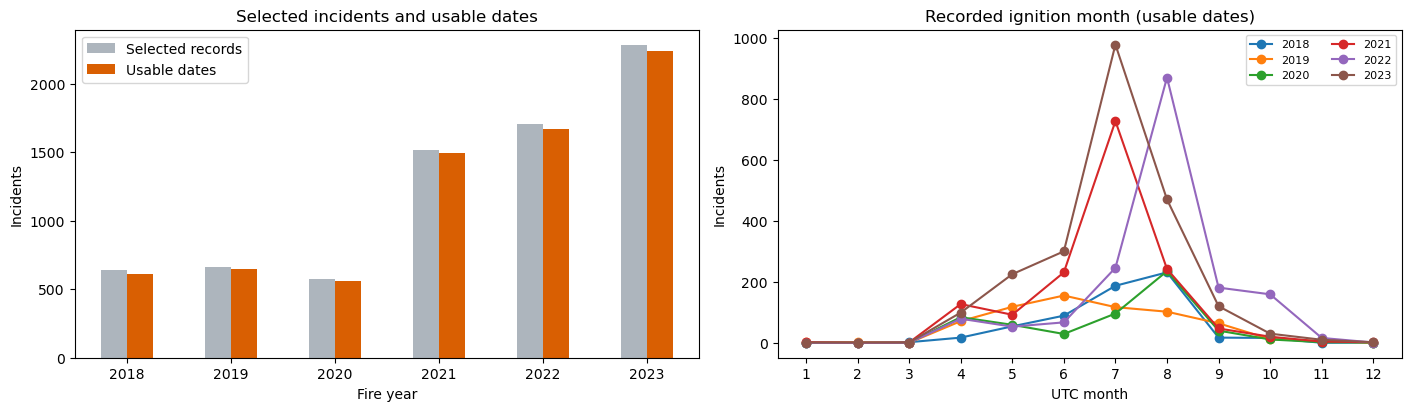

,year,h3_cell,incident_count
4708,2022,8728dedb2ffffff,6
4216,2022,8712dc62affffff,5
6141,2023,8712d5382ffffff,4
3156,2021,8728dedb2ffffff,4
3492,2022,8712c2034ffffff,4
1262,2020,87128942bffffff,4
3327,2022,871289ae3ffffff,4
1837,2021,871288249ffffff,4
6112,2023,8712d4c34ffffff,4
2976,2021,8712f652dffffff,3


In [3]:
yearly = pd.DataFrame({'Selected records': selected.groupby('FIRE_YEAR').size(),
                       'Usable dates': incidents.groupby('year').size()}).fillna(0).astype(int)
monthly = incidents.groupby(['year', 'month']).size().rename('incidents').reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
yearly.plot.bar(ax=axes[0], color=['#adb5bd', '#d95f02'])
axes[0].set(title='Selected incidents and usable dates', xlabel='Fire year', ylabel='Incidents')
axes[0].tick_params(axis='x', rotation=0)
for year, group in monthly.groupby('year'):
    counts = group.set_index('month').incidents.reindex(range(1, 13), fill_value=0)
    axes[1].plot(counts.index, counts.values, marker='o', label=str(year))
axes[1].set(title='Recorded ignition month (usable dates)', xlabel='UTC month', ylabel='Incidents', xticks=range(1, 13))
axes[1].legend(ncol=2, fontsize=8)
fig.savefig(OUTPUT / 'incident_counts.png', dpi=150)
plt.show()

cell_counts = incidents.groupby(['year', 'h3_cell']).event_key.nunique().rename('incident_count').reset_index()
assert int(cell_counts.incident_count.sum()) == len(incidents)
cell_counts.to_csv(OUTPUT / 'incident_h3_counts_by_year.csv', index=False)
display(cell_counts.sort_values('incident_count', ascending=False).head(10))

## Kamloops boundary and map settings

Same cached Fire Centre boundary, H3 polygons, orange logarithmic colour scale, and 2-2 layout as notebook 02. Spatial membership uses the incident point. Empty cells mean no mapped incident in the selected period, not verified absence of fire.

In [4]:
boundary_path = ROOT / 'data/region_exploration/fire_centres.geojson'
assert boundary_path.exists(), f'Missing cached Fire Centre boundary: {boundary_path}'
regions_json = json.loads(boundary_path.read_text(encoding='utf-8'))
region_feature = next(f for f in regions_json['features']
                      if f['properties']['MOF_FIRE_CENTRE_NAME'] == REGION_NAME)
geometry = make_valid(shape(region_feature['geometry']))

def boundary_polygons(geom):
    if geom.geom_type == 'Polygon':
        yield geom
    else:
        for part in getattr(geom, 'geoms', []):
            yield from boundary_polygons(part)

region_incidents = incidents.loc[intersects_xy(
    geometry, incidents.point_longitude.to_numpy(), incidents.point_latitude.to_numpy())].copy()
min_lon, min_lat, max_lon, max_lat = geometry.bounds
lon_limits = (min_lon - .08, max_lon + .08)
lat_limits = (min_lat - .08, max_lat + .08)
aspect_lat = geometry.centroid.y
incident_cmap = LinearSegmentedColormap.from_list('incident_oranges', plt.get_cmap('Oranges')(np.linspace(.35, 1, 256)))
print(f'{REGION_NAME}: {len(region_incidents):,} usable dated incidents across 2018-2023')
display(region_incidents.groupby('year').size().rename('incidents').to_frame())

def plot_incident_panels(counts_by_period, title, colorbar_label, output_name):
    assert len(counts_by_period) == 4, 'Choose four panels.'
    maximum = max((int(s.max()) for s in counts_by_period.values() if not s.empty), default=1)
    norm = LogNorm(vmin=1, vmax=max(2, maximum))
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True, constrained_layout=True)
    for ax, (label, counts) in zip(axes.flat, counts_by_period.items()):
        for polygon in boundary_polygons(geometry):
            ax.plot(*polygon.exterior.xy, color='gray', linewidth=.8, zorder=2)
            for ring in polygon.interiors:
                ax.plot(*ring.xy, color='gray', linewidth=.6, zorder=2)
        if not counts.empty:
            polygons = [[(lon, lat) for lat, lon in h3.cell_to_boundary(cell)] for cell in counts.index]
            ax.add_collection(PolyCollection(polygons, array=counts.to_numpy(dtype=float),
                                              cmap=incident_cmap, norm=norm, edgecolors='none'))
        else:
            ax.text(.5, .5, 'No mapped incidents', transform=ax.transAxes, ha='center', va='center')
        ax.set(title=f'{label} ({int(counts.sum()):,} incidents)', xlabel='Longitude', ylabel='Latitude',
               xlim=lon_limits, ylim=lat_limits)
        ax.set_aspect(1 / np.cos(np.deg2rad(aspect_lat)))
        ax.set_axisbelow(True)
        ax.grid(True, linestyle=':', linewidth=.6, color='gray', alpha=.4)
    ticks = list(range(1, min(maximum, 8) + 1)) if maximum <= 8 else None
    colorbar = fig.colorbar(ScalarMappable(norm=norm, cmap=incident_cmap), ax=axes.ravel().tolist(),
                 label=colorbar_label, shrink=.85, ticks=ticks)
    if ticks is not None:
        colorbar.ax.yaxis.set_major_formatter(ScalarFormatter())
        colorbar.ax.yaxis.set_minor_locator(NullLocator())
    fig.suptitle(title, fontsize=14)
    fig.savefig(OUTPUT / output_name, dpi=150)
    plt.show()

Kamloops Fire Centre: 1,642 usable dated incidents across 2018-2023


,incidents
year,
2018,247
2019,106
2020,112
2021,355
2022,443
2023,379


## Monthly recorded incident starts: Kamloops, June-September 2023

Shared colour scale across the four months. A location is coloured only in its recorded ignition month; it is not shown as active throughout the incident's lifetime.

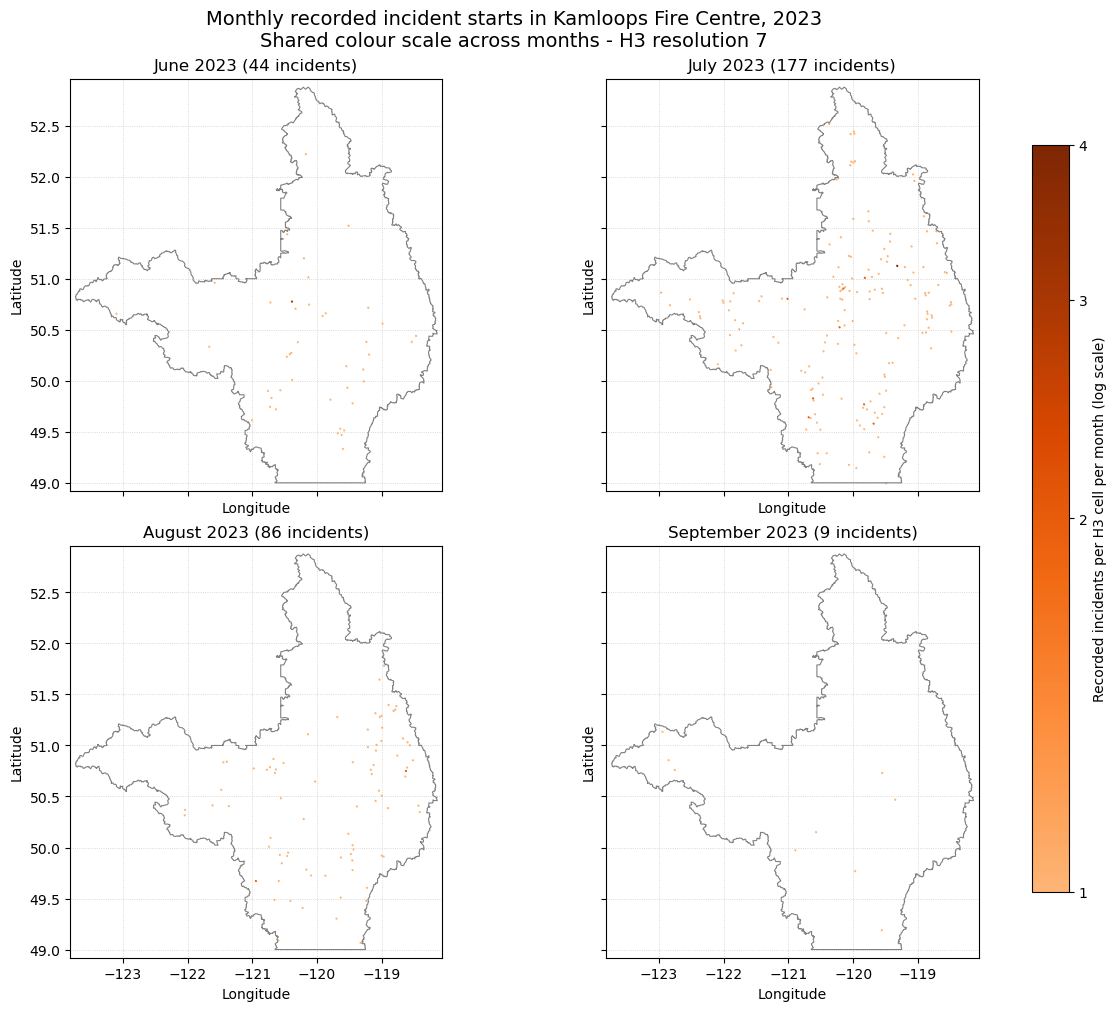

In [5]:
monthly_window = region_incidents.loc[
    region_incidents.year.eq(SELECTED_YEAR) & region_incidents.month.isin(MONTHS)]
monthly_counts = {
    f'{calendar.month_name[month]} {SELECTED_YEAR}':
        monthly_window.loc[monthly_window.month.eq(month)].groupby('h3_cell').event_key.nunique()
    for month in MONTHS
}
assert sum(int(s.sum()) for s in monthly_counts.values()) == len(monthly_window)
plot_incident_panels(monthly_counts,
    f'Monthly recorded incident starts in {REGION_NAME}, {SELECTED_YEAR}\nShared colour scale across months - H3 resolution {H3_RESOLUTION}',
    'Recorded incidents per H3 cell per month (log scale)', 'kamloops_monthly_incidents_2023.png')

## Weekly recorded incident starts: Kamloops, August 2023

August 1-7, 8-14, 15-21, and 22-31, matching notebook 02. The last period has ten days, so raw counts are not equal-duration comparisons.

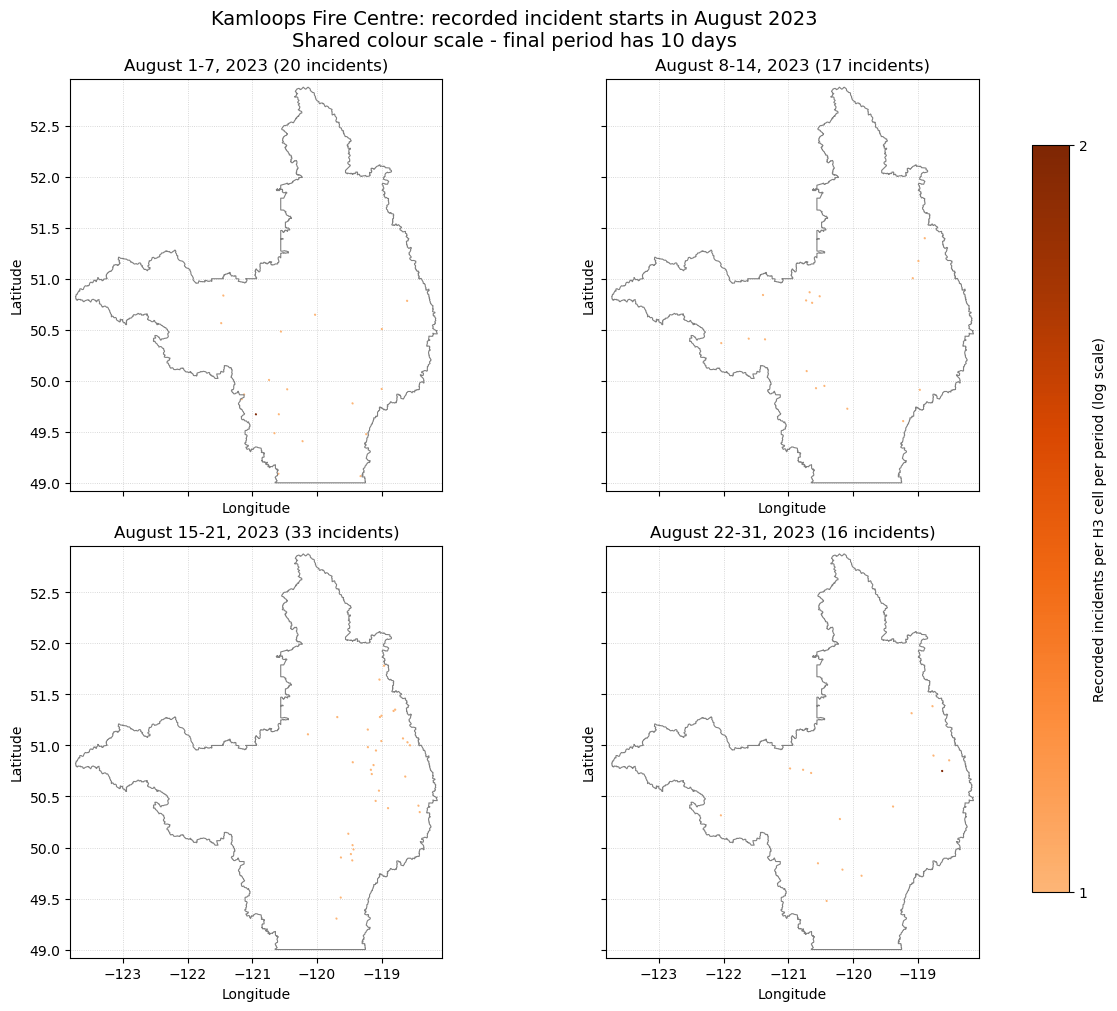

In [6]:
weekly_window = region_incidents.loc[region_incidents.year.eq(SELECTED_YEAR) & region_incidents.month.eq(8)]
week_ranges = [(1, 7), (8, 14), (15, 21), (22, 31)]
weekly_counts = {
    f'August {start}-{end}, {SELECTED_YEAR}':
        weekly_window.loc[weekly_window.ignition_date.dt.day.between(start, end)].groupby('h3_cell').event_key.nunique()
    for start, end in week_ranges
}
assert sum(int(s.sum()) for s in weekly_counts.values()) == len(weekly_window)
plot_incident_panels(weekly_counts,
    f'{REGION_NAME}: recorded incident starts in August {SELECTED_YEAR}\nShared colour scale - final period has 10 days',
    'Recorded incidents per H3 cell per period (log scale)', 'kamloops_weekly_incidents_2023.png')